<div style="font-family:'Google Sans','Roboto','Segoe UI',sans-serif; background:#FFFFFF; border:1px solid #DADCE0; border-radius:14px; overflow:hidden; box-shadow:0 2px 6px rgba(60,64,67,0.10); margin-bottom:20px;">
  <div style="display:flex; height:6px; width:100%;">
    <div style="flex:1; background:#4285F4;"></div>
    <div style="flex:1; background:#EA4335;"></div>
    <div style="flex:1; background:#FBBC04;"></div>
    <div style="flex:1; background:#34A853;"></div>
  </div>
  <div style="padding:22px 26px 18px 26px;">
    <div style="display:flex; flex-wrap:wrap; justify-content:space-between; align-items:center; gap:10px; margin-bottom:10px;">
      <span style="background:#E8F0FE; color:#1A73E8; font-weight:700; font-size:11px; letter-spacing:0.9px; text-transform:uppercase; padding:5px 12px; border-radius:999px; border:1px solid #D2E3FC;">
        ROBINA MIRBAHAR &middot; GOOGLE DEVELOPER EXPERT
      </span>
      <span style="color:#5F6368; font-size:12px; font-weight:500;">
        NSF / NSO &middot; Solar Filament Segmentation Challenge 2026
      </span>
    </div>
    <div style="font-size:22px; font-weight:700; color:#202124; line-height:1.25; margin-bottom:6px;">
      MAGFiLO Panoptic Solar Filament Segmentation &middot; Limb-Corrected H-&alpha; Physics &amp; Tree-DP Selection
    </div>
    <div style="font-size:14px; color:#5F6368; line-height:1.5; margin-bottom:16px;">
      End-to-end reproducible Python &amp; PyTorch implementation of my 3-stage panoptic pipeline (<b>Stage P:</b> 72-Ray Kasa Limb Fit, 128-Bin CLV Flat-Fielding &amp; &sigma;=48 Contrast &rarr; <b>Stage N:</b> 3-Head scSE U-Net + Pyramid Pooling + soft-clDice &rarr; <b>Stage H:</b> 7-Superlevel Component Tree, 3-Fold LightGBM Expected-PQ Calibration &amp; Bottom-Up Tree-DP Antichain)
    </div>
    <div style="display:grid; grid-template-columns:repeat(auto-fit, minmax(175px, 1fr)); gap:12px; margin-top:12px;">
      <div style="background:#FFFFFF; border:1px solid #DADCE0; border-top:3px solid #1A73E8; border-radius:10px; padding:12px 14px; box-shadow:0 1px 2px rgba(60,64,67,0.06);">
        <div style="font-size:11px; font-weight:700; color:#5F6368; text-transform:uppercase; letter-spacing:0.6px;">3-Fold Date-Grouped OOF</div>
        <div style="font-size:17px; font-weight:700; color:#202124; margin:4px 0 2px 0;">0.3252 PQ &middot; 0.6295 SQ</div>
        <div style="font-size:12px; color:#1A73E8; font-weight:500;">+59.6% over 0.2038 raw baseline</div>
      </div>
      <div style="background:#FFFFFF; border:1px solid #DADCE0; border-top:3px solid #1E8E3E; border-radius:10px; padding:12px 14px; box-shadow:0 1px 2px rgba(60,64,67,0.06);">
        <div style="font-size:11px; font-weight:700; color:#5F6368; text-transform:uppercase; letter-spacing:0.6px;">Selected Kaggle Submission</div>
        <div style="font-size:17px; font-weight:700; color:#202124; margin:4px 0 2px 0;">0.30 Public LB &middot; RQ 0.5166</div>
        <div style="font-size:12px; color:#1E8E3E; font-weight:500;">Ref 58343725 (submission_pq_optimal.csv)</div>
      </div>
      <div style="background:#FFFFFF; border:1px solid #DADCE0; border-top:3px solid #9334E6; border-radius:10px; padding:12px 14px; box-shadow:0 1px 2px rgba(60,64,67,0.06);">
        <div style="font-size:11px; font-weight:700; color:#5F6368; text-transform:uppercase; letter-spacing:0.6px;">Stored Repo Checkpoints</div>
        <div style="font-size:17px; font-weight:700; color:#202124; margin:4px 0 2px 0;">67.82 MB Total</div>
        <div style="font-size:12px; color:#9334E6; font-weight:500;">3&times; FP16 U-Net + 3&times; Fold LightGBM</div>
      </div>
      <div style="background:#FFFFFF; border:1px solid #DADCE0; border-top:3px solid #F9AB00; border-radius:10px; padding:12px 14px; box-shadow:0 1px 2px rgba(60,64,67,0.06);">
        <div style="font-size:11px; font-weight:700; color:#5F6368; text-transform:uppercase; letter-spacing:0.6px;">Zero-Retrain Reproduction</div>
        <div style="font-size:17px; font-weight:700; color:#202124; margin:4px 0 2px 0;">--predict-only Ready</div>
        <div style="font-size:12px; color:#E37400; font-weight:500;">180 GONG test disks &middot; MIT Licensed</div>
      </div>
    </div>
  </div>
</div>

<div style="font-family:'Google Sans','Roboto','Segoe UI',sans-serif; margin:22px 0 12px 0; padding:10px 14px; background:#F8F9FA; border-left:4px solid #1A73E8; border-radius:0 8px 8px 0;">
  <div style="font-size:11px; font-weight:700; color:#1A73E8; text-transform:uppercase; letter-spacing:0.8px;">Section 01</div>
  <div style="font-size:17px; font-weight:700; color:#202124; margin-top:1px;">Environment, Google Material-3 Chart Styling &amp; Stored Checkpoint Verification</div>
  <div style="font-size:12.5px; color:#5F6368; margin-top:2px;">Import modular <code>src/magfilo_panoptic</code> components, configure Material-3 figure aesthetics, and verify all stored neural + LightGBM weights in <code>./weights/</code></div>
</div>

### 1.1 Three-Stage Modular Architecture (`src/magfilo_panoptic/`)
1. **Stage P (`preprocessing.py`):** 72-ray 50%-limb crossing + Kasa circle regression for `(cx, cy, R)`, 128-bin radial median Center-to-Limb Variation (CLV) flat-fielding, off-limb masking (`r > 0.995 R`), normalized-convolution chromospheric absorption contrast `(B_sigma48 - F) / B_sigma48`, and heliocentric cosine `mu`.
2. **Stage N (`network.py`):** 3-head (`fg`, `spine`, `sep`) `MagfiloPanopticUNet` (`resnet18` encoder, `3 -> 8` stride-1 detail stem, `160`-ch Pyramid Pooling bottleneck, `(96, 64, 40, 24)` scSE attention decoders) trained with boundary-upweighted `BCE + SoftDice` and `0.25 * soft_clDice` (Shit et al., CVPR 2021).
3. **Stage H (`postprocessing.py`, `metrics.py`, `rle.py`):** 7-superlevel laminar component tree on `P_eff = clip(0.75 P_fg + 0.25 P_spine - 0.35 P_sep, 0, 1)`, astrophysical sunspot rejection, 3-fold date-grouped LightGBM expected-PQ regressor `u_hat(c)` over 31 features, exact bottom-up Tree-DP antichain selection (`tau* = 0.205`), and spine-tangent corridor bridging (`gap <= 14 px`).

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='.*IProgress not found.*')

import matplotlib.image as mpimg
import matplotlib.pyplot as plt

# Apply Google Developer Material-3 Light Chart Theme
plt.rcParams.update({
    'figure.facecolor': '#FFFFFF',
    'axes.facecolor': '#F8F9FA',
    'axes.edgecolor': '#DADCE0',
    'axes.linewidth': 0.9,
    'axes.labelcolor': '#202124',
    'axes.titlesize': 11.5,
    'axes.titleweight': 'bold',
    'xtick.color': '#5F6368',
    'ytick.color': '#5F6368',
})

REPO_ROOT = Path('.').resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import magfilo_panoptic as mp
print('Loaded magfilo_panoptic:', mp.__all__)

WEIGHTS_DIR = REPO_ROOT / 'weights'
with open(WEIGHTS_DIR / 'postproc_config.json', 'r', encoding='utf-8') as f:
    postproc_cfg = json.load(f)
print('Stored postproc_config.json:', json.dumps({
    k: postproc_cfg[k] for k in ('backbone', 'accelerator', 'infer_size', 'test_ensemble_folds', 'tau_optimal', 'tau_high_precision')
}, indent=2))
for p in sorted(WEIGHTS_DIR.iterdir()):
    print(f'  {p.name}: {p.stat().st_size / (1024 ** 2):.3f} MB')

Loaded magfilo_panoptic: ['IMG_SIZE', 'FEATURE_NAMES', 'encode_rle_counts', 'decode_rle_counts', 'rle_dict_from_counts', 'compute_exact_magfilo_metrics', 'estimate_solar_disk', 'preprocess_solar_disk', 'disk_crop_box', 'MagfiloPanopticUNet', 'SolarMultiTaskLoss', 'soft_cldice_loss', 'extract_disk_component_tree', 'solve_tree_dp_antichain', 'apply_spine_bridging_to_selection', 'train_and_evaluate_oof_lgbm']
Stored postproc_config.json: {
  "backbone": "resnet18",
  "accelerator": "gpu_t4",
  "infer_size": 1536,
  "test_ensemble_folds": 3,
  "tau_optimal": 0.20500000000000002,
  "tau_high_precision": 0.24000000000000002
}
  lgb_scorer.txt: 0.317 MB
  lgb_scorer_fold0.txt: 0.346 MB
  lgb_scorer_fold1.txt: 0.224 MB
  lgb_scorer_fold2.txt: 0.379 MB
  postproc_config.json: 0.001 MB
  unet_fold0_fp16.pt: 22.607 MB
  unet_fold1_fp16.pt: 22.607 MB
  unet_fold2_fp16.pt: 22.607 MB


<div style="font-family:'Google Sans','Roboto','Segoe UI',sans-serif; margin:22px 0 12px 0; padding:10px 14px; background:#F8F9FA; border-left:4px solid #1E8E3E; border-radius:0 8px 8px 0;">
  <div style="font-size:11px; font-weight:700; color:#1E8E3E; text-transform:uppercase; letter-spacing:0.8px;">Section 02</div>
  <div style="font-size:17px; font-weight:700; color:#202124; margin-top:1px;">Zero-Retrain Prediction Reproduction (<code>--predict-only --weights-dir ./weights</code>)</div>
  <div style="font-size:12.5px; color:#5F6368; margin-top:2px;">Load all 3 FP16 U-Net fold checkpoints + 3 LightGBM expected-PQ boosters directly from <code>./weights/</code> to generate verified RLE submission CSVs</div>
</div>

To reproduce the exact Kaggle test submission (`submission_pq_optimal.csv`, ref `58343725`) on the 180 competition test disks without retraining, pass `--data-root /path/to/MAGFiLO_1.0_Kaggle_2026` in place of `--dry-run` below:
```bash
python train_magfilo_panoptic.py \
  --predict-only \
  --weights-dir ./weights \
  --data-root /path/to/MAGFiLO_1.0_Kaggle_2026 \
  --out-dir ./predictions
```

In [2]:
# Reproduce test inference from stored ./weights/ without retraining.
# Replace '--dry-run' with '--data-root /path/to/filament-segmentation-2026' for competition test images,
# or drop '--predict-only --weights-dir ./weights' to retrain all 3 folds from scratch.
import subprocess

TRAIN_SCRIPT = REPO_ROOT / 'train_magfilo_panoptic.py'
DRY_OUT = REPO_ROOT / 'dry_run_out'
subprocess.run(
    [
        sys.executable,
        str(TRAIN_SCRIPT),
        '--predict-only',
        '--weights-dir', str(WEIGHTS_DIR),
        '--dry-run',
        '--out-dir', str(DRY_OUT),
    ],
    check=True,
)
with open(DRY_OUT / 'predict_summary.json', 'r', encoding='utf-8') as f:
    summary = json.load(f)
summary['weights_dir'] = os.path.relpath(summary['weights_dir'], REPO_ROOT).replace('\\', '/')
for rep in summary.get('submissions', {}).values():
    if 'path' in rep:
        rep['path'] = os.path.relpath(rep['path'], REPO_ROOT).replace('\\', '/')
print(json.dumps(summary, indent=2))

{
  "mode": "predict_only",
  "accelerator": "cpu",
  "weights_dir": "weights",
  "backbone": "resnet18",
  "infer_size": 512,
  "n_unet_folds": 3,
  "n_lgbm_boosters": 3,
  "tau_optimal": 0.20500000000000002,
  "tau_high_precision": 0.24000000000000002,
  "n_test_disks": 2,
  "runtime_sec": 30.95,
  "submissions": {
    "submission_pq_optimal.csv": {
      "path": "dry_run_out/submission_pq_optimal.csv",
      "n_rows": 2,
      "n_disks": 2
    },
    "submission_high_precision.csv": {
      "path": "dry_run_out/submission_high_precision.csv",
      "n_rows": 2,
      "n_disks": 2
    },
    "submission_spine_bridged.csv": {
      "path": "dry_run_out/submission_spine_bridged.csv",
      "n_rows": 2,
      "n_disks": 2
    }
  }
}


<div style="font-family:'Google Sans','Roboto','Segoe UI',sans-serif; margin:22px 0 12px 0; padding:10px 14px; background:#F8F9FA; border-left:4px solid #F9AB00; border-radius:0 8px 8px 0;">
  <div style="font-size:11px; font-weight:700; color:#E37400; text-transform:uppercase; letter-spacing:0.8px;">Section 03</div>
  <div style="font-size:17px; font-weight:700; color:#202124; margin-top:1px;">3-Fold Date-Grouped OOF Quantitative Rubric &amp; Qualitative Morphology Panels</div>
  <div style="font-size:12.5px; color:#5F6368; margin-top:2px;">Panoptic Quality (PQ = SQ &times; RQ), IoU &amp; Dice distributions, 1:n vs n:1 multiplicity histograms, and GONG H-&alpha; validation disk overlays</div>
</div>

| Pipeline Operating Point | 3-Fold OOF PQ | OOF SQ | OOF RQ | Mean / Median IoU | Mean / Median Dice | Public LB PQ |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| Raw `P_eff >= 0.40` Connected Components | `0.2038` | `0.6152` | `0.3313` | `0.4330 / 0.4453` | `0.5801 / 0.6162` | -- |
| Stage H Tree-DP High-Precision (`tau = 0.240`) | `0.3231` | `0.6306` | `0.5124` | `0.5210 / 0.5561` | `0.6655 / 0.7147` | -- |
| **Stage H Tree-DP PQ-Optimal (`tau* = 0.205`)** | **`0.3252`** | **`0.6295`** | **`0.5166`** | **`0.5163 / 0.5508`** | **`0.6611 / 0.7104`** | **`0.30` (ref `58343725`)** |

Inspecting metrics from: assets
{
  "pq_optimal": {
    "pq": 0.3251663610686334,
    "sq": 0.6294571097830959,
    "rq": 0.5165822357311719,
    "tp": 3824,
    "fp": 2782,
    "fn": 4375,
    "iou_mean": 0.5163104371127635,
    "iou_p25": 0.41806914350490704,
    "iou_p50": 0.5508396741339102,
    "iou_p75": 0.6471293613348884,
    "dice_mean": 0.6610890835898492,
    "dice_p25": 0.5896315312665686,
    "dice_p50": 0.7103760403140797,
    "dice_p75": 0.7857662847019034,
    "gt_1_to_0_miss": 2321,
    "gt_1_to_1": 5597,
    "gt_1_to_many": 281,
    "pred_0_to_1_fp": 652,
    "pred_1_to_1": 5734,
    "pred_many_to_1": 219,
    "gt_degree_hist": {
      "0": 2321,
      "1": 5597,
      "2": 247,
      "3": 33,
      "4": 1
    },
    "pred_degree_hist": {
      "0": 652,
      "1": 5734,
      "2": 197,
      "3": 22
    }
  },
  "high_precision": {
    "pq": 0.32307877084777353,
    "sq": 0.6305661340538667,
    "rq": 0.5123630233211576,
    "tp": 3647,
    "fp": 2390,
    "fn": 4552

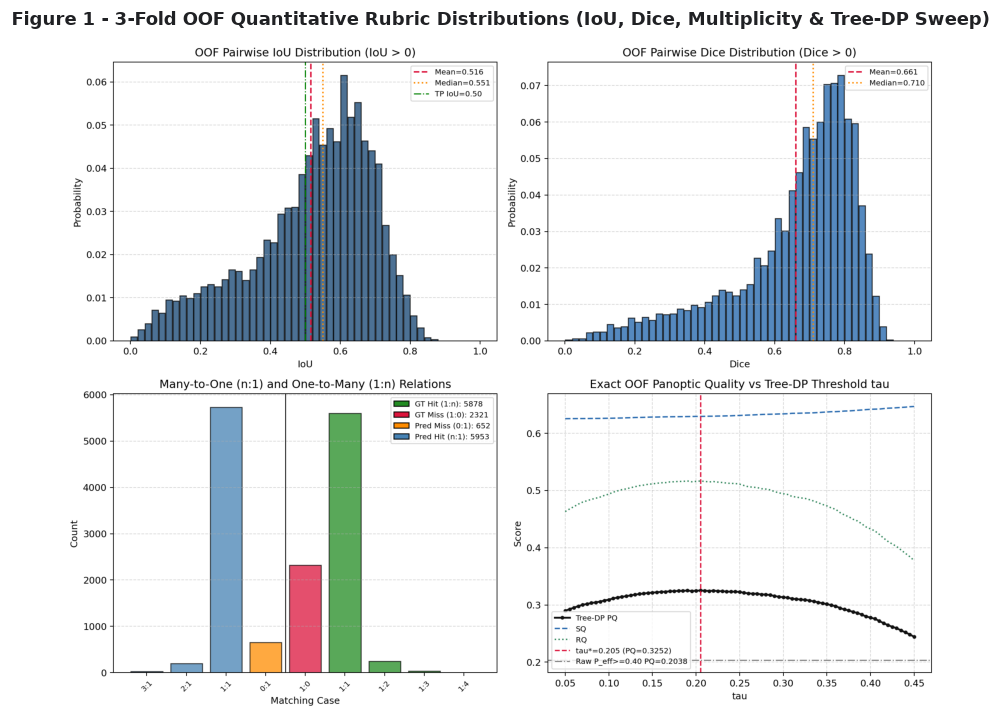

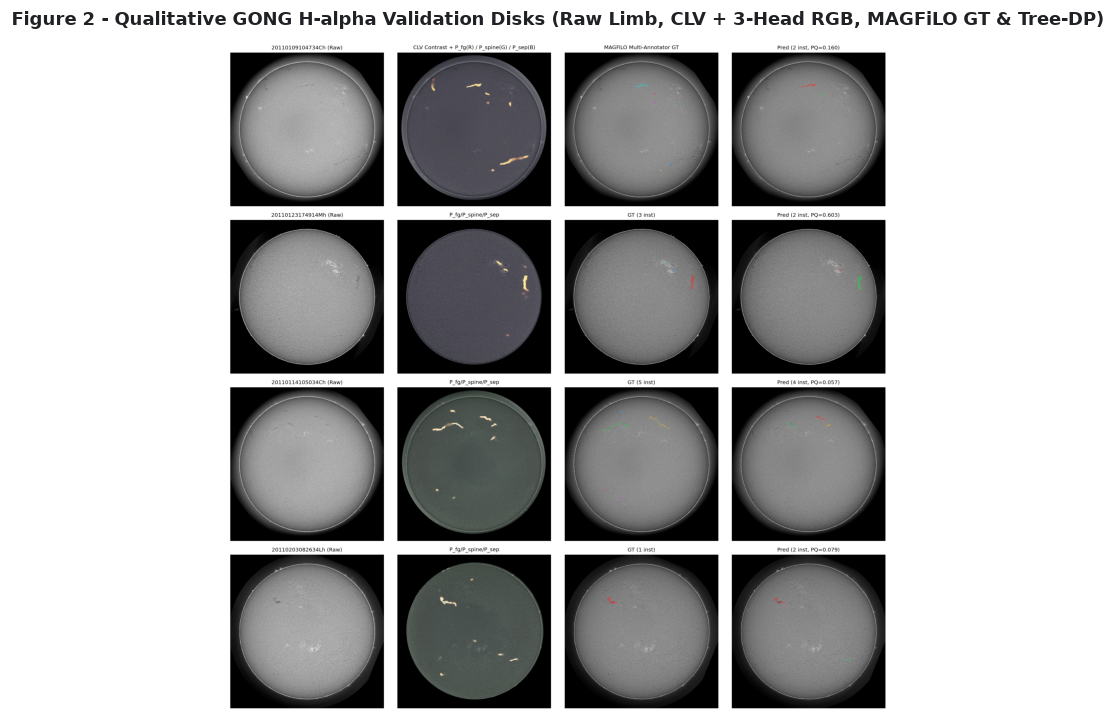

In [3]:
OUT_DIR = None
for cand in [REPO_ROOT / 'assets', REPO_ROOT / 'out', REPO_ROOT.parent / 'out', REPO_ROOT / 'dry_run_out']:
    if (cand / 'run_metrics.json').exists():
        OUT_DIR = cand
        break

plot_titles = {
    'quantitative_rubric_histograms.png': 'Figure 1 - 3-Fold OOF Quantitative Rubric Distributions (IoU, Dice, Multiplicity & Tree-DP Sweep)',
    'qualitative_morphology_panels.png': 'Figure 2 - Qualitative GONG H-alpha Validation Disks (Raw Limb, CLV + 3-Head RGB, MAGFiLO GT & Tree-DP)',
}

if OUT_DIR is not None:
    rel_out = os.path.relpath(OUT_DIR, REPO_ROOT).replace('\\', '/')
    print('Inspecting metrics from:', rel_out)
    with open(OUT_DIR / 'run_metrics.json', 'r', encoding='utf-8') as f:
        metrics = json.load(f)
    print(json.dumps(metrics['oof_metrics'], indent=2))
    for png_name, plot_title in plot_titles.items():
        p = OUT_DIR / png_name
        if p.exists():
            fig, ax = plt.subplots(figsize=(11, 6.4), dpi=115)
            ax.imshow(mpimg.imread(p))
            ax.axis('off')
            ax.set_title(plot_title, pad=10, color='#202124')
            plt.tight_layout()
            plt.show()
else:
    print('No full training run_metrics.json found locally; predict-only outputs verified in: dry_run_out')

---
### Official NSF / NSO & GONG Data Acknowledgment
This work utilizes GONG data obtained by the NSO Integrated Synoptic Program, managed by the National Solar Observatory, which is operated by the Association of Universities for Research in Astronomy (AURA), Inc. under a cooperative agreement with the National Science Foundation and with contribution from the National Oceanic and Atmospheric Administration. The GONG network of instruments is hosted by the Big Bear Solar Observatory, High Altitude Observatory, Learmonth Solar Observatory, Udaipur Solar Observatory, Instituto de Astrofísica de Canarias, and Cerro Tololo Interamerican Observatory. The organization of the Filament Segmentation Challenge 2026 is partially supported by the U.S. National Science Foundation (NSF) under Grant No. 2209912 and 2433781, directorate for Computer and Information Science and Engineering (CSE), and Office of Advanced Cyberinfrastructure (OAC), and Grant No. 2511630, AST Division Of Astronomical Sciences and MPS Directorate for Mathematical and Physical Sciences, and sponsored by the U.S. National Science Foundation (NSF) National Solar Observatory (NSO).

<div align="center" style="font-family:'Google Sans','Roboto','Segoe UI',sans-serif; background:#FFFFFF; border:1px solid #DADCE0; border-radius:14px; overflow:hidden; box-shadow:0 2px 6px rgba(60,64,67,0.08); margin-top:20px;">
  <div style="display:flex; height:5px; width:100%;">
    <div style="flex:1; background:#4285F4;"></div>
    <div style="flex:1; background:#EA4335;"></div>
    <div style="flex:1; background:#FBBC04;"></div>
    <div style="flex:1; background:#34A853;"></div>
  </div>
  <div style="padding:18px 24px;">
    <div style="font-size:15px; font-weight:700; color:#202124; margin-bottom:4px;">
      📚 Co-Author of <i>AI Engineering: From Classical ML to RAG &amp; Agentic AI Systems</i> (2026)
    </div>
    <div style="font-size:13.5px; color:#3C4043; margin-bottom:6px;">
      👩‍💻 <b>Robina Mirbahar</b> &middot; AI/ML Google Developer Expert (GDE) 🇵🇰 &middot; Google Cloud Champion Innovator &middot; Microsoft Certified Trainer
    </div>
    <div style="font-size:12.5px; color:#5F6368; margin-bottom:10px;">
      🎤 International Speaker &nbsp;|&nbsp; 📝 Technical Author &nbsp;|&nbsp; 🚀 Mentor @ Google for Startups &amp; Women Techmakers Ambassador
    </div>
    <div style="font-size:13px; font-weight:600;">
      <a href="https://github.com/RobinaMirbahar/magfilo-panoptic-seg" style="color:#1A73E8; text-decoration:none;">MAGFiLO Panoptic Repo (@RobinaMirbahar)</a>
      &nbsp;&middot;&nbsp;
      <a href="https://www.kaggle.com/robinamirbahar" style="color:#1A73E8; text-decoration:none;">Kaggle (@robinamirbahar)</a>
      &nbsp;&middot;&nbsp;
      <a href="https://www.linkedin.com/in/robinamirbahar" style="color:#1A73E8; text-decoration:none;">LinkedIn (in/robinamirbahar)</a>
    </div>
  </div>
</div>